# HST Calibration Assignment  

In [1]:
import os
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

### Loading Files and Creating Dictionary

In [2]:
cal_folder= Path("hst-calibration/")
processed_folder = Path("hst-processed/")

cal_set = {
    "ubai2505m": os.path.join(cal_folder, "ubai2505m"),
    "ubai2507m": os.path.join(cal_folder, "ubai2507m"),
    "ubai2508m": os.path.join(cal_folder, "ubai2508m"),
}

science_folder = Path("hst-processed") / "Provided Science Ready Files"

science_ready_files = {
    Path(f).stem.split("_")[0]: science_folder/f
    for f in os.listdir(science_folder)
    if f.lower().endswith(".fits")
}

In [3]:
def load_calibration_files(cal_sets):
    result = {}

    for name, cal_path in cal_sets.items():
        folder = Path(cal_path)

        file_dict = {
            Path(f).stem.rsplit("_", 1)[-1].upper(): folder/f
            for f in os.listdir(folder)
        }

        result[name] = file_dict

    return result

cal_file_dict = load_calibration_files(cal_set)


In [4]:
cal_file_dict, science_ready_files 

({'ubai2505m': {'ATODFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_atodfile.fits'),
   'BIASFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_biasfile.fits'),
   'BLEVFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_blevfile.fits'),
   'DARKFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_darkfile.fits'),
   'FLATFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_flatfile.fits'),
   'MASKFILE': WindowsPath('hst-calibration/ubai2505m/ubai2505m_maskfile.fits'),
   'RAW': WindowsPath('hst-calibration/ubai2505m/ubai2505m_raw.fits')},
  'ubai2507m': {'ATODFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_atodfile.fits'),
   'BIASFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_biasfile.fits'),
   'BLEVFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_blevfile.fits'),
   'DARKFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_darkfile.fits'),
   'FLATFILE': WindowsPath('hst-calibration/ubai2507m/ubai2507m_flatfile.fits'),
   'MASKFIL

In [5]:
def load_fits(path):
    with fits.open(path) as hdul:
        main_header = hdul[0].header

        # finds extension with data in it
        for hdu in hdul:
            if hdu.data is not None:
                return hdu.data.astype(float), main_header
            
paths = cal_file_dict['ubai2508m']
raw, raw_header = load_fits(paths['RAW'])
bias, bias_header = load_fits(paths['BIASFILE'])
mask, mask_header = load_fits(paths['MASKFILE'])
blev, blev_header = load_fits(paths['BLEVFILE'])
flat, flat_header = load_fits(paths['FLATFILE'])
dark, dark_header = load_fits(paths['DARKFILE'])

1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


### For Visualisation...

In [6]:
def show_image(img, title, vmin=0, vmax=20):
    plt.figure(figsize=(6,6))
    plt.imshow(img, cmap="inferno", origin="lower", vmin=vmin, vmax=vmax)
    plt.title(title)
    plt.colorbar()
    plt.show()


# for viewing result
def per_norm(image, pmax=99, pmin=1):

    res = np.asarray(image, dtype=np.float64)
    vmin, vmax = np.percentile(image, (pmin, pmax))
    norm = (res - vmin) / (vmax - vmin)

    return np.clip(norm, 0, 1)

### 1. Mask invalid data with MASKFILE

In [7]:
def apply_mask(raw_chip, mask_chip):
    masked = raw_chip.copy()
    masked[mask_chip != 0] = np.nan
    return masked

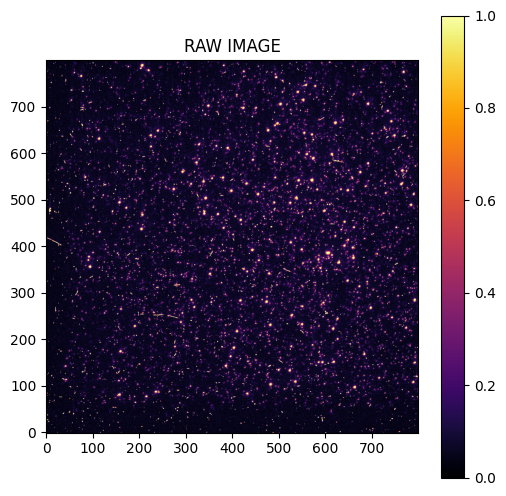

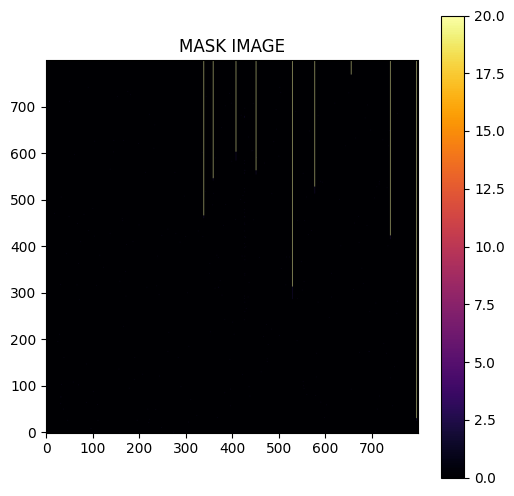

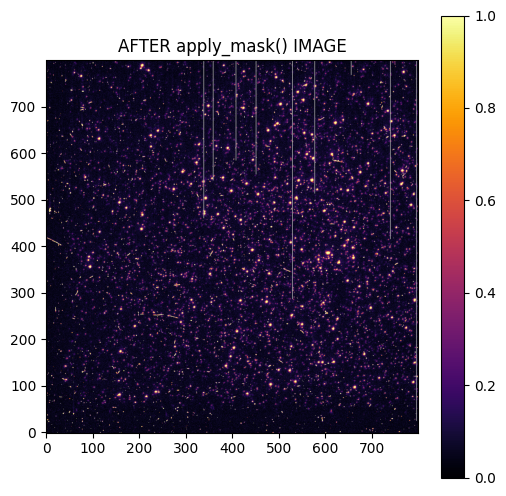

In [8]:
raw1 = per_norm(raw[0])
masked1 = apply_mask(raw1, mask[0])
masked = apply_mask(raw[0], mask[0]) # actually used for further calibration

#adding normalisation to see result better
show_image(raw1, 'RAW IMAGE', None, None)
show_image(mask[0], 'MASK IMAGE')
show_image(masked1, 'AFTER apply_mask() IMAGE', None, None)

### 3. Bias level with BLEVFILE

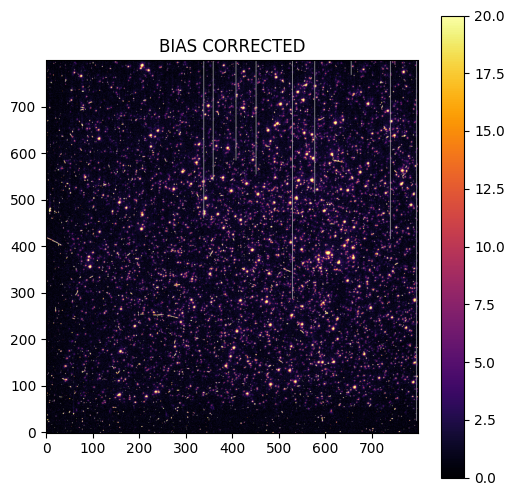

In [9]:
def parse_blev_file(blev, chip=0):

    # handles both (4, 800, 14) and (800, 14) shaped files
    if blev.ndim == 3:
        overscan = blev[chip][9:790, 8:14]
    else:
        overscan = blev[9:790, 8:14]

    overscan[overscan == 0] = np.nan
    odd_vals = overscan[:, 1::2]
    even_vals = overscan[:, ::2]

    return np.mean(odd_vals), np.mean(even_vals)


  #---------------------------------------------------------------------

def apply_bias_corr(image, odd_mean, even_mean):

  corrected = image.copy()
  ny, nx = corrected.shape
    
  for x in range(nx):
    if x % 2 == 0:
      corrected[:, x] -= odd_mean
    else:      
      corrected[:, x] -= even_mean

  return corrected

odd_mean, even_mean = parse_blev_file(blev, chip=0)
bias_corrected = apply_bias_corr(masked, odd_mean, even_mean)
show_image(bias_corrected, "BIAS CORRECTED")

<!-- ### 4. Remove bias image with BIASFILE -->

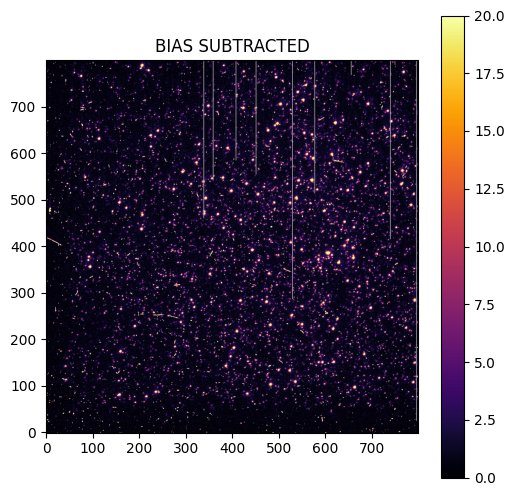

In [10]:
def subtract_bias(image, bias):
    return image - bias

bias_subtracted = subtract_bias(bias_corrected, bias[0])
show_image(bias_subtracted, 'BIAS SUBTRACTED')

### 5. Subtract dark with DARKFILE 

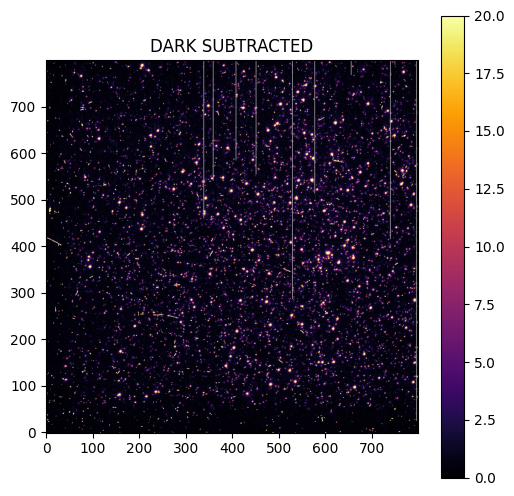

In [11]:
def subtract_dark(image, dark, exptime):
    return image - dark*exptime

exptime = raw_header["EXPTIME"]
dark_corrected = subtract_dark(bias_subtracted, dark[0], exptime)
show_image(dark_corrected, 'DARK SUBTRACTED')

### 6. Flatfield correction with FLATFILE

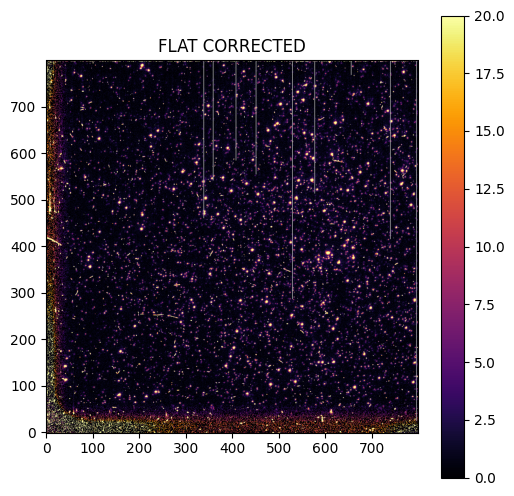

In [12]:
def apply_flat(image, flat):
    return image*flat

flat_corrected = apply_flat(dark_corrected, flat[0])
show_image(flat_corrected, 'FLAT CORRECTED')

### Photometry calibration with PHOTTAB

In [13]:
phottab_data = {
    "Filter": ["F336W", "F555W"],
    "PHOTFLAM": [1.115396e-16, 6.920538e-18],
    "PHOTZPT": [-21.1, -21.1], 
    "PHOTPLAM": [3359.474, 5442.934],
    "PHOTBW": [204.4908, 522.2513],
    "ZP_CORR": [-0.03288031, 0.02655506]
}

phottab = pd.DataFrame(phottab_data)

filter = raw_header['FILTNAM1']
file_phot = phottab.loc[phottab["Filter"] == filter].iloc[0]
PHOTFLAM = float(file_phot["PHOTFLAM"])
PHOTZPT  = float(file_phot["PHOTZPT"])
ZP_CORR  = float(file_phot["ZP_CORR"])

C:\Users\odunu\AppData\Local\Temp\ipykernel_12216\2151463750.py:3: RuntimeWarning: invalid value encountered in log10
  mag = -2.5 * np.log10(flux) + photzpt + zp_corr


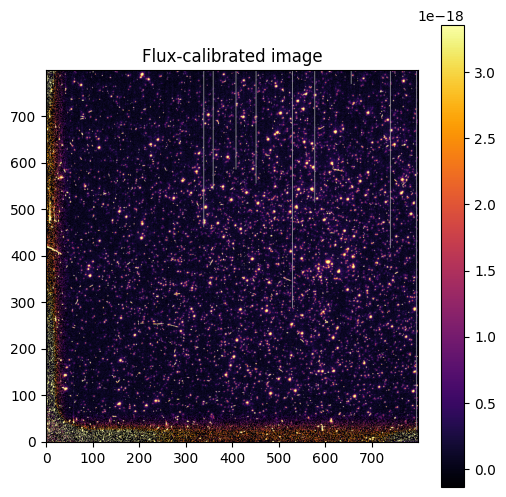

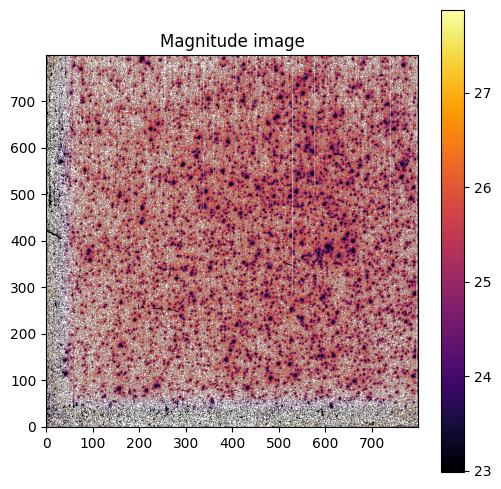

In [31]:
def apply_photometry(image, exptime, photflam, photzpt, zp_corr):
    flux = (image / exptime)*photflam
    mag = -2.5 * np.log10(flux) + photzpt + zp_corr
    return flux, mag

flux, mag = apply_photometry(flat_corrected, exptime, PHOTFLAM, PHOTZPT, ZP_CORR)
lo, hi = np.nanpercentile(flux, [5, 98])
show_image(flux, "Flux-calibrated image", lo, hi)
lo, hi = np.nanpercentile(mag, [5, 98])
show_image(mag, "Magnitude image", lo, hi)

In [ ]:
()